In [1]:
# CPU/GPU selection: run this cell before importing jax or mgp elsewhere.
# After changing MODE, restart the kernel and run all cells from the top.
# GPU mode requires CUDA-enabled JAX in a Linux/WSL2 kernel.
import os

MODE = "cpu"  # "cpu" or "gpu"
if MODE not in {"cpu", "gpu"}:
    raise ValueError('MODE must be "cpu" or "gpu".')

# Keep CPU available in GPU mode for operations explicitly placed on CPU.
os.environ["JAX_PLATFORMS"] = "cpu" if MODE == "cpu" else "cuda,cpu"

import jax
backend = jax.default_backend()
if backend != MODE:
    raise RuntimeError("Device mode has changed: restart the kernel and run all cells.")
print("Backend:", backend)
print("Devices:", jax.devices())

Backend: cpu
Devices: [CpuDevice(id=0)]


# Demo 1: `mgp` unified interface — block loadings (test1 design)

**Model** (Bhattacharya & Dunson 2011, "Sparse Bayesian infinite factor models"):
$x_i = B\eta_i + \varepsilon_i$, $\eta_i \sim \mathcal N_K(0, I)$,
$\varepsilon_i \sim \mathcal N_p(0, \Omega)$, $\Omega$ diagonal, with the
multiplicative gamma process (MGP) prior on the loadings,

$$B_{jk} \mid \omega_{jk}, T_k \sim \mathcal N\big(0,\,(\omega_{jk} T_k)^{-1}\big),\qquad
\omega_{jk} \sim \Gamma(\nu/2, \nu/2),\qquad
T_k = \prod_{\ell \le k} \delta_\ell,\quad \delta_1 \sim \Gamma(a_1, 1),\ \delta_{\ell \ge 2} \sim \Gamma(a_2, 1),$$

so the prior precision of column $k$ accumulates with the column index:
redundant trailing columns are shrunk toward zero and an over-fitted
truncation level $K$ is enough.

**Data design** (`test1`, $n = 100 \ll p = 1956$, $r = 5$ true factors):

- column $k$ of the true loading matrix $B_0$ equals 1 on 500 consecutive rows starting at row $364(k-1)$ — five partially overlapping blocks;
- $\Omega_0 = I_p$ (homoscedastic noise), $\Sigma_0 = B_0 B_0^\top + \Omega_0$.

**Inference** through the unified `mgp` interface, on the SAME data:

- `GibbsMGP` — the Gibbs sampler of Bhattacharya & Dunson (2011), Section 3.1 (exact MCMC);
- `CaviMGP` — the CAVI algorithm of `MGP_CAVI.md` (fast deterministic approximation).

Shown: automatic factor-dimension selection, noise/covariance/subspace recovery, covariance heatmaps, posterior covariance uncertainty, the CAVI ELBO trajectory, MCMC mixing diagnostics (ESS via ArviZ), and factor-switching diagnostics (RSP alignment, aligned counts, all column infinity norms, and paired factor scores).

In [2]:
import sys
import time
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

# Locate the repository root from __file__ when available, otherwise walk
# upward from the working directory, and put the mgp package on sys.path.
try:
    root = Path(__file__).resolve().parents[1]
except NameError:
    root = None
if root is None or not (root / "mgp" / "__init__.py").is_file():
    root = next((d for d in (Path.cwd(), *Path.cwd().parents)
                 if (d / "mgp" / "__init__.py").is_file()), None)
if root is None:
    raise RuntimeError(
        "cannot locate the mgp package; open the repository or one of its "
        "subdirectories as the working directory")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import jax
from mgp import CaviMGP, GibbsMGP

# Consistent, publication-friendly plotting style shared by both demos.
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#5b6472",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6eaf0",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlepad": 8,
    "axes.labelsize": 10,
    "axes.labelcolor": "#30363f",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "xtick.color": "#30363f",
    "ytick.color": "#30363f",
    "legend.fontsize": 9,
    "legend.frameon": False,
    "font.family": "DejaVu Sans",
})
C_GIBBS, C_CAVI, C_TRUE, C_SHRUNK = "#2f6fd0", "#e07b39", "#b03a2e", "#c9d3df"

print("package root:", root, "| jax backend:", jax.default_backend())

package root: C:\Users\kexio\Documents\GitHub\MGP_BFM | jax backend: cpu


## 1. Simulate the data (same design, new random seed)

In [3]:
DATA_SEED = 11
SAMPLER_SEED = 2026
np.random.seed(DATA_SEED)
print(f"Seeds: data={DATA_SEED}, Gibbs/scores={SAMPLER_SEED}")

P, K0, N = 1956, 5, 100
B_0 = np.zeros((P, K0))
for j in range(K0):
    B_0[364 * j: 364 * j + 500, j] = 1.0
cov_0 = B_0 @ B_0.T + np.eye(P)                # Sigma_0 = B_0 B_0' + I
X = np.random.multivariate_normal(np.zeros(P), cov_0, N)

Sig_true = cov_0
s2_true = np.diag(cov_0) - (B_0 ** 2).sum(1)   # = 1 for every variable
print(f"X: {X.shape}  (n = {N}, p = {P}, true factors r = {K0})")

Seeds: data=11, Gibbs/scores=2026


X: (100, 1956)  (n = 100, p = 1956, true factors r = 5)


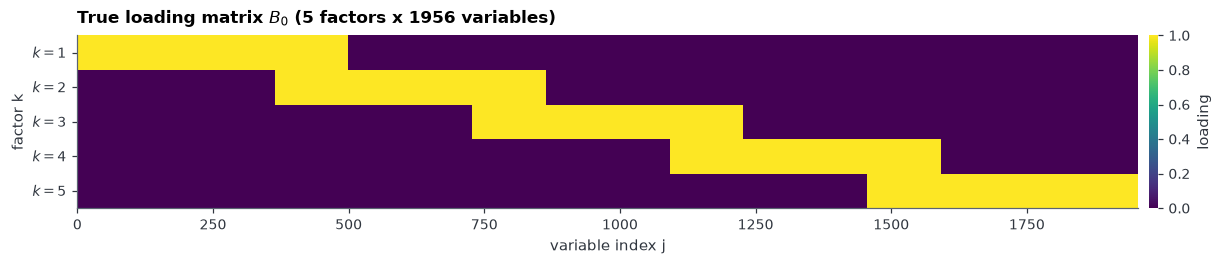

In [4]:
fig, ax = plt.subplots(figsize=(11, 2.3), constrained_layout=True)
im = ax.imshow(B_0.T, aspect="auto", interpolation="nearest", cmap="viridis")
ax.set_title(f"True loading matrix $B_0$ ({K0} factors x {P} variables)", loc="left")
ax.set_xlabel("variable index j")
ax.set_ylabel("factor k")
ax.set_yticks(np.arange(K0))
ax.set_yticklabels([f"$k={k + 1}$" for k in range(K0)])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("loading")
cb.outline.set_visible(False)
plt.show()

## 2. Fit both estimators on the same data

- Truncation level **K = 50**, deliberately larger than the true r = 5: the increasing shrinkage of the MGP prior should push redundant columns toward zero;
- both estimators explicitly use `nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1`, the common MGP prior settings used throughout this demo;
- both use `center=True, standardize=False`: the shared base class centers once, and all recovery diagnostics remain on the original simulated scale;
- `GibbsMGP` uses `precision="float32"`, `n_iter=20000, burn_in=10000, thin=10` (1000 retained draws), and `seed=SAMPLER_SEED`; `CaviMGP` is deterministic and uses `precision="float64"`, `max_iter=1000, tol=1e-1`;
- the first `GibbsMGP` call includes one-time XLA ahead-of-time compilation (**not** counted in `runtime_sec_`).

CAVI checks the absolute change in the variable ELBO after each complete sweep: `abs(Lvar_t - Lvar_prev) < tol`, with `tol=1e-1`. The independent `drop_budget` (default 0.5 when left as `None`) rejects larger ELBO decreases with `FloatingPointError` instead of reporting convergence. All diagnostics below use these settings.

In [5]:
K = 50  # truncation level, over-fitted on purpose (true r = 5)
LINF_THRESHOLD = 0.1

# Exact MCMC: Gibbs sampler (Bhattacharya & Dunson, Section 3.1).
t0 = time.perf_counter()
gs = GibbsMGP(
    K=K, nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1,
    center=True, standardize=False, precision="float32",
    n_iter=20000, burn_in=10000, thin=10,
    seed=SAMPLER_SEED, verbose=False,
).fit(X)
wall_gs = time.perf_counter() - t0
S = gs.B_samples_.shape[0]

# Fast deterministic approximation: CAVI (MGP_CAVI.md).
t0 = time.perf_counter()
vi = CaviMGP(
    K=K, nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1,
    center=True, standardize=False, precision="float64",
    max_iter=1000, tol=1e-1, verbose=False,
).fit(X)
wall_vi = time.perf_counter() - t0

print("-" * 104)
print(f"GibbsMGP | {S} kept draws | scan {gs.runtime_sec_:.1f}s "
      f"({1e3 * gs.runtime_sec_ / 20000:.1f} ms/sweep) | wall {wall_gs:.1f}s "
      f"| precision={gs.precision_used_}")
print(f"CaviMGP  | converged={vi.converged_} ({vi.stop_reason_}) in "
      f"{vi.n_iter_} sweeps | ELBO={vi.elbo_[-1]:.1f} | loop {vi.runtime_sec_:.1f}s "
      f"| wall {wall_vi:.1f}s | precision={vi.precision_used_}")
print("-" * 104)

--------------------------------------------------------------------------------------------------------
GibbsMGP | 1000 kept draws | scan 1220.6s (61.0 ms/sweep) | wall 1226.1s | precision=float32
CaviMGP  | converged=True (tol) in 945 sweeps | ELBO=-311868.8 | loop 102.5s | wall 105.2s | precision=float64
--------------------------------------------------------------------------------------------------------


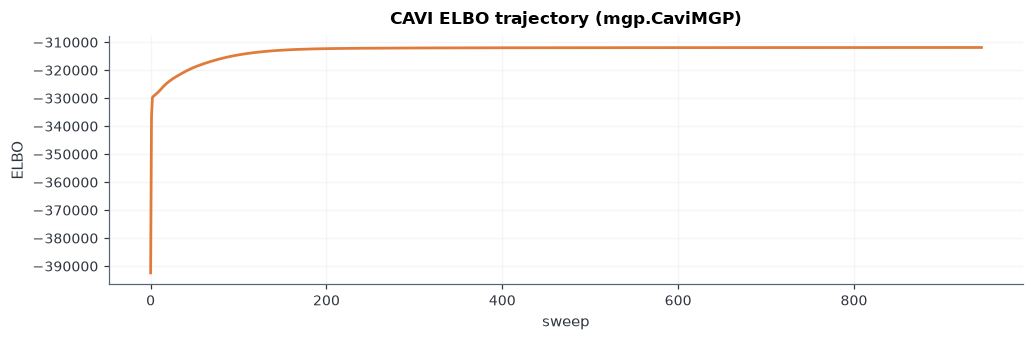

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 3.2))
vi.plot_elbo(ax=ax, show=False, title="CAVI ELBO trajectory (mgp.CaviMGP)")
ax.lines[0].set_color(C_CAVI)
ax.lines[0].set_linewidth(1.8)
ax.grid(True, alpha=0.45)
plt.show()

## 3. Automatic selection of the factor dimension

The plots show the posterior mean column L2 norms $\frac{1}{S}\sum_s \|B_{\cdot k}^{(s)}\|_2$ (Gibbs) and $\|\mu_{\cdot k}\|_2$ (CAVI). These norms visualize the shrinkage; the factor counts below use the following selection rules.

- **Gibbs:** `gs.n_factors()` uses empirical marginal credible intervals over the retained draws.
- **CAVI, credible:** `vi.n_factors(method="credible")` activates a column when at least one Gaussian marginal credible interval excludes zero.
- **CAVI, linf:** `vi.n_factors(method="linf", threshold=0.1)` activates a column when $\max_j |\mu_{jk}| > 0.1$. Equality is inactive. This uses the variational mean's column infinity norm, rather than the L2 norms plotted above, and does not use posterior uncertainty.

The output compares all three counts with the true factor dimension $r=5$; the rules can give different results. The printed `vi.T_` values are a supplementary global-shrinkage diagnostic in the original coordinates, not a fourth formal factor-count rule.

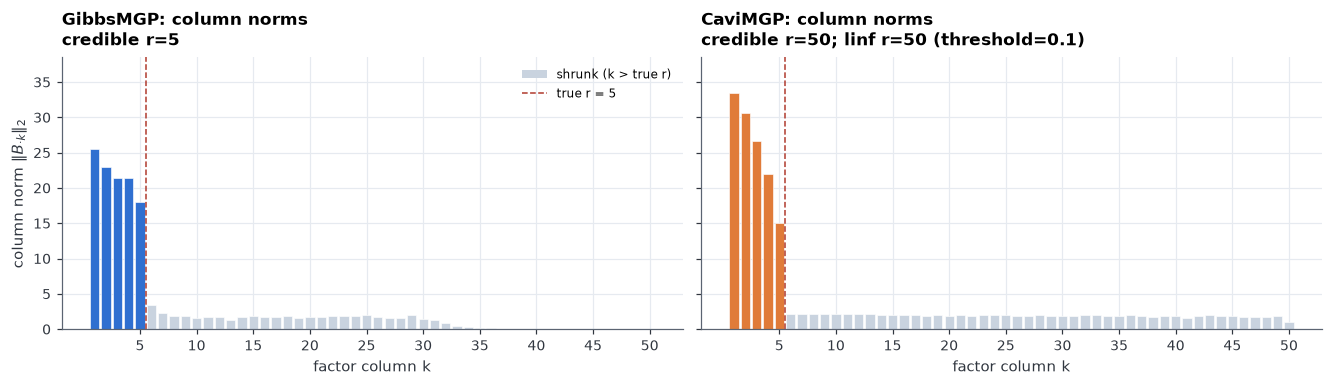

column norms (Gibbs): [2.5457e+01 2.3002e+01 2.1353e+01 2.1468e+01 1.7957e+01 3.3960e+00
 2.2460e+00 1.8640e+00 1.8870e+00 1.6080e+00 1.6570e+00 1.7350e+00
 1.3690e+00 1.7110e+00 1.8100e+00 1.7180e+00 1.7120e+00 1.9300e+00
 1.5990e+00 1.7460e+00 1.7560e+00 1.8800e+00 1.8040e+00 1.8690e+00
 2.0320e+00 1.7270e+00 1.5340e+00 1.6310e+00 1.9670e+00 1.4560e+00
 1.3040e+00 8.1100e-01 5.1200e-01 2.9800e-01 2.0800e-01 1.4200e-01
 7.9000e-02 5.1000e-02 2.7000e-02 2.3000e-02 1.9000e-02 1.0000e-02
 6.0000e-03 3.0000e-03 2.0000e-03 1.0000e-03 1.0000e-03 0.0000e+00
 0.0000e+00 0.0000e+00]
column norms (CAVI):  [33.469 30.597 26.715 21.981 15.01   2.092  2.106  2.102  2.148  2.081
  2.105  2.188  2.094  2.     1.984  2.012  2.055  1.931  1.962  1.872
  2.036  1.868  1.992  2.011  1.974  1.837  1.795  1.943  1.915  1.934
  1.835  1.951  2.039  1.929  1.822  2.     1.87   1.663  1.867  1.904
  1.619  1.929  2.039  1.796  1.821  1.785  1.658  1.722  1.854  1.006]
true factor count: 5
Gibbs n_factors (cr

In [7]:
r_gs_credible = gs.n_factors()
r_vi_credible = vi.n_factors(method="credible")
r_vi_linf = vi.n_factors(method="linf", threshold=LINF_THRESHOLD)

colnorm_gs = np.linalg.norm(gs.B_samples_, axis=1).mean(0)
colnorm_vi = np.linalg.norm(vi.mu_, axis=0)

# Use a linear axis without a logarithmic transform or artificial floor.
all_norms = (colnorm_gs, colnorm_vi)
ymax = max(float(n.max()) for n in all_norms) * 1.15


def _draw_colnorms(ax, norms, count_label, color, title):
    xs = np.arange(1, len(norms) + 1)
    ax.bar(xs, norms, width=0.82,
           color=np.where(xs <= K0, color, C_SHRUNK),
           edgecolor="white", linewidth=0.4)
    ax.axvline(K0 + 0.5, color=C_TRUE, ls="--", lw=1.0)
    ax.set_title(f"{title}: column norms\n{count_label}", loc="left")
    ax.set_xlabel("factor column k")
    ax.set_ylim(0, ymax)
    ax.set_xticks(np.arange(5, len(norms) + 1, 5))


fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), constrained_layout=True,
                         sharey=True)
_draw_colnorms(axes[0], colnorm_gs, f"credible r={r_gs_credible}",
               C_GIBBS, "GibbsMGP")
_draw_colnorms(axes[1], colnorm_vi,
               f"credible r={r_vi_credible}; linf r={r_vi_linf} "
               f"(threshold={LINF_THRESHOLD:g})",
               C_CAVI, "CaviMGP")
axes[0].set_ylabel(r"column norm $\|B_{\cdot k}\|_2$")

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

handles = [
    Patch(facecolor=C_SHRUNK, label="shrunk (k > true r)"),
    Line2D([0], [0], color=C_TRUE, ls="--", lw=1.0,
           label=f"true r = {K0}"),
]
axes[0].legend(handles=handles, loc="upper right", fontsize=8)
plt.show()

print("column norms (Gibbs):", np.round(colnorm_gs, 3))
print("column norms (CAVI): ", np.round(colnorm_vi, 3))
print(f"true factor count: {K0}")
print(f"Gibbs n_factors (credible): {r_gs_credible}")
print(f"CAVI n_factors (credible): {r_vi_credible}")
print(f"CAVI n_factors (linf, threshold={LINF_THRESHOLD:g}): {r_vi_linf}")
print("CAVI global shrinkage E_q[T_k] (supplementary, original coordinates):")
print(np.array2string(vi.T_, precision=1))

## 4. Recovery of $\sigma^2$, the covariance matrix, and the factor subspace

For each estimator, report both the plug-in covariance and the posterior-mean covariance using
\[
\text{Frobenius error}=\|\widehat\Sigma-\Sigma_0\|_F,
\qquad
\text{relative Frobenius error}
=\frac{\|\widehat\Sigma-\Sigma_0\|_F}{\|\Sigma_0\|_F}.
\]
The table and plots below report both errors **before RSP alignment**. The absolute error retains the covariance scale; the relative error normalizes by the same true-covariance norm for all four estimates. The subspace check uses the top-$r$ estimated columns **by loading norm**, rather than assuming that the signal occupies the first $r$ columns.

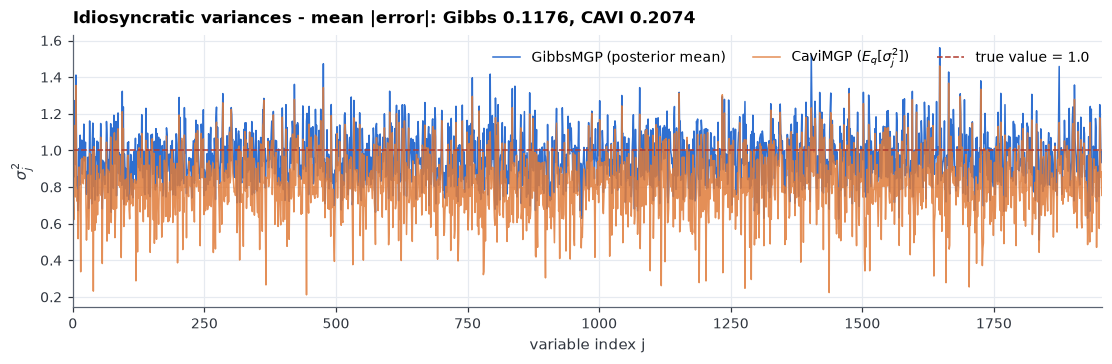

In [8]:
err_gs = np.abs(gs.sigma2_hat_ - s2_true).mean()
err_vi = np.abs(vi.sigma2_hat_ - s2_true).mean()

fig, ax = plt.subplots(figsize=(10, 3.2), constrained_layout=True)
ax.plot(gs.sigma2_hat_, color=C_GIBBS, lw=1.0, label="GibbsMGP (posterior mean)")
ax.plot(vi.sigma2_hat_, color=C_CAVI, lw=1.0, alpha=0.85,
        label=r"CaviMGP ($E_q[\sigma_j^2]$)")
ax.axhline(float(s2_true[0]), color=C_TRUE, ls="--", lw=1.0,
           label=f"true value = {s2_true[0]:.1f}")
ax.set_xlabel("variable index j")
ax.set_ylabel(r"$\sigma_j^2$")
ax.set_title(f"Idiosyncratic variances - mean |error|: "
             f"Gibbs {err_gs:.4f}, CAVI {err_vi:.4f}", loc="left")
ax.set_xlim(0, P - 1)
ax.legend(loc="upper right", ncol=3)
plt.show()

Covariance estimation errors before RSP alignment
||Sigma_true||_F = 1185.294900
Estimator / summary             Frobenius error   Relative Frobenius error
GibbsMGP plug-in                     419.836648                   0.354204
GibbsMGP Sigma_mean_                 420.053008                   0.354387
CaviMGP plug-in                      899.988489                   0.759295
CaviMGP Sigma_mean_                  900.145834                   0.759428
principal-angle cosines (GibbsMGP, top-5 columns by norm): [0.988  0.9863 0.9829 0.9787 0.9656]
principal-angle cosines (CaviMGP, top-5 columns by norm): [0.9879 0.9862 0.9826 0.9786 0.9651]


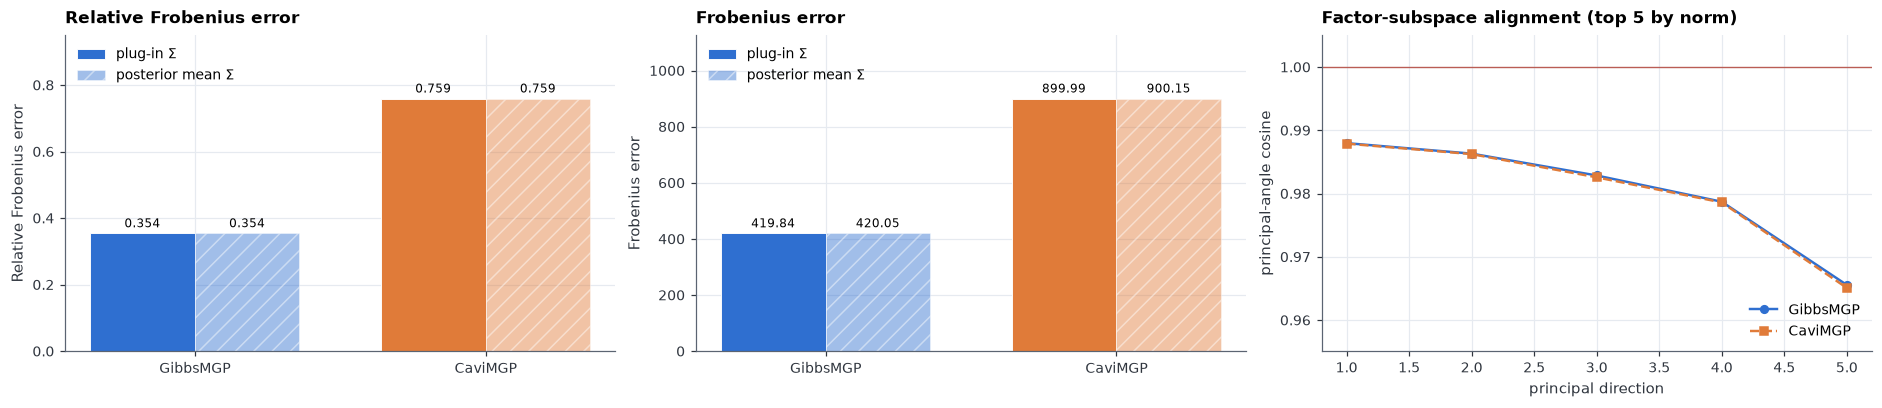

In [9]:
# Covariance recovery before RSP alignment: plug-in and posterior mean.
Sig_gs_mean = gs.Sigma_mean_
Sig_vi_mean = vi.Sigma_mean_
norm_Sig_true = float(np.linalg.norm(Sig_true, ord="fro"))


def froerr(Sig):
    return float(np.linalg.norm(Sig - Sig_true, ord="fro"))


def relerr(Sig):
    return froerr(Sig) / norm_Sig_true


fro_gs_plug, fro_gs_mean = froerr(gs.Sigma_), froerr(Sig_gs_mean)
fro_vi_plug, fro_vi_mean = froerr(vi.Sigma_), froerr(Sig_vi_mean)
rel_gs_plug, rel_gs_mean = fro_gs_plug / norm_Sig_true, fro_gs_mean / norm_Sig_true
rel_vi_plug, rel_vi_mean = fro_vi_plug / norm_Sig_true, fro_vi_mean / norm_Sig_true
covariance_errors = {
    "GibbsMGP plug-in": (fro_gs_plug, rel_gs_plug),
    "GibbsMGP Sigma_mean_": (fro_gs_mean, rel_gs_mean),
    "CaviMGP plug-in": (fro_vi_plug, rel_vi_plug),
    "CaviMGP Sigma_mean_": (fro_vi_mean, rel_vi_mean),
}
print("Covariance estimation errors before RSP alignment")
print(f"||Sigma_true||_F = {norm_Sig_true:.6f}")
print(f"{'Estimator / summary':<26} {'Frobenius error':>20} {'Relative Frobenius error':>26}")
for label, (absolute, relative) in covariance_errors.items():
    print(f"{label:<26} {absolute:20.6f} {relative:26.6f}")

# Principal angles between the true space and the span of the top-r
# estimated loading columns by norm (1 = aligned).
U_true = np.linalg.qr(B_0)[0][:, :K0]
cos_gs, cos_vi = [], []
for name, Bh, store in (("GibbsMGP", gs.B_hat_, cos_gs),
                        ("CaviMGP", vi.B_hat_, cos_vi)):
    top = np.argsort(np.linalg.norm(Bh, axis=0))[::-1][:K0]
    U_post = np.linalg.qr(Bh[:, top])[0][:, :K0]
    cosines = np.linalg.svd(U_post.T @ U_true, compute_uv=False)
    store.extend(cosines.tolist())
    print(f"principal-angle cosines ({name}, top-{K0} columns by norm):",
          np.round(cosines, 4))

fig, axes = plt.subplots(1, 3, figsize=(17, 3.6), constrained_layout=True)
x = np.arange(2)
width = 0.36
panels = (
    (axes[0], [rel_gs_plug, rel_vi_plug], [rel_gs_mean, rel_vi_mean],
     "Relative Frobenius error", "%.3f"),
    (axes[1], [fro_gs_plug, fro_vi_plug], [fro_gs_mean, fro_vi_mean],
     "Frobenius error", "%.2f"),
)
for ax, plug_in, posterior_mean, label, number_format in panels:
    b1 = ax.bar(x - width / 2, plug_in, width,
                color=[C_GIBBS, C_CAVI], edgecolor="white", linewidth=0.6,
                label=r"plug-in $\Sigma$")
    b2 = ax.bar(x + width / 2, posterior_mean, width,
                color=[C_GIBBS, C_CAVI], alpha=0.45, hatch="//",
                edgecolor="white", linewidth=0.6,
                label=r"posterior mean $\Sigma$")
    ax.set_xticks(x)
    ax.set_xticklabels(["GibbsMGP", "CaviMGP"])
    ax.set_ylabel(label)
    ax.set_title(label, loc="left")
    ax.set_ylim(0, 1.25 * max(*plug_in, *posterior_mean))
    ax.legend(loc="upper left")
    for bars in (b1, b2):
        ax.bar_label(bars, fmt=number_format, padding=2, fontsize=8)

axes[2].plot(np.arange(1, K0 + 1), cos_gs, "o-", ms=5, lw=1.6,
             color=C_GIBBS, label="GibbsMGP")
axes[2].plot(np.arange(1, K0 + 1), cos_vi, "s--", ms=5, lw=1.6,
             color=C_CAVI, label="CaviMGP")
axes[2].axhline(1.0, color=C_TRUE, lw=0.9, alpha=0.8)
axes[2].set_ylim(min(min(cos_gs), min(cos_vi)) - 0.01, 1.005)
axes[2].set_xlabel("principal direction")
axes[2].set_ylabel("principal-angle cosine")
axes[2].set_title(f"Factor-subspace alignment (top {K0} by norm)", loc="left")
axes[2].legend(loc="lower right")
plt.show()

## 4b. Covariance heatmaps: truth vs posterior means

Heatmaps of (a) the true covariance $\Sigma_0$, (b) the Gibbs posterior-mean covariance $E[\Sigma\mid X]$ (`gs.Sigma_mean_`) and (c) the CAVI posterior-mean covariance $E_q[\Sigma]$ (`vi.Sigma_mean_`). All panels share one color scale, with the upper limit set by the pooled 99.5th percentile.

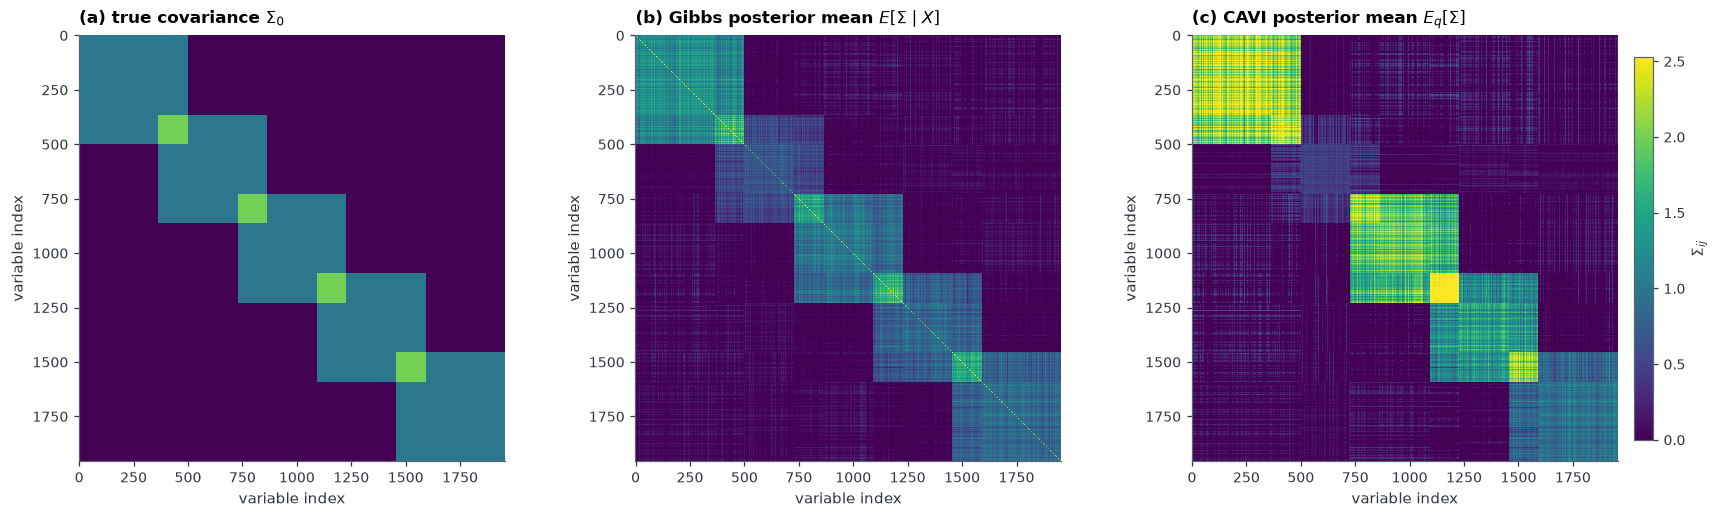

In [10]:
panels = (
    (r"(a) true covariance $\Sigma_0$", Sig_true),
    (r"(b) Gibbs posterior mean $E[\Sigma\mid X]$", Sig_gs_mean),
    (r"(c) CAVI posterior mean $E_q[\Sigma]$", Sig_vi_mean),
)
vmax = float(np.percentile(
    np.concatenate([np.asarray(M, dtype=float).ravel() for _, M in panels]),
    99.5,
))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
for ax, (title, M) in zip(axes, panels):
    im = ax.imshow(M, cmap="viridis", vmin=0.0, vmax=vmax,
                   interpolation="nearest")
    ax.set_title(title, loc="left")
    ax.set_xlabel("variable index")
    ax.set_ylabel("variable index")
    ax.grid(False)
cb = fig.colorbar(im, ax=axes, pad=0.01, shrink=0.9)
cb.set_label(r"$\Sigma_{ij}$")
plt.show()

## 4c. Posterior uncertainty of $\Sigma$

Both estimators expose posterior moments of $\Sigma = BB^\top + \Omega$: `Sigma_mean_` (posterior mean), `Sigma_var_`/`Sigma_sd_` (entrywise posterior variance and standard deviation) and `cov_Sigma(pairs)` (selected entry-pair covariances). For `GibbsMGP` these are Monte Carlo estimates from the retained draws; for `CaviMGP` they are closed-form moments of the mean-field variational posterior. Diagonal variances (`Sigma_diag_var_`) and selected pair covariances always use all Gibbs draws; the full $p \times p$ variance matrix is additionally guarded by a compute budget for large $p$.

posterior SD of Sigma_jj: Gibbs mean = 0.303, CAVI mean = 0.324
Gibbs: Var(Sigma_01) = 5.585e-02, Cov(Sigma_01, Sigma_23) = 2.945e-02 (all 1000 draws)


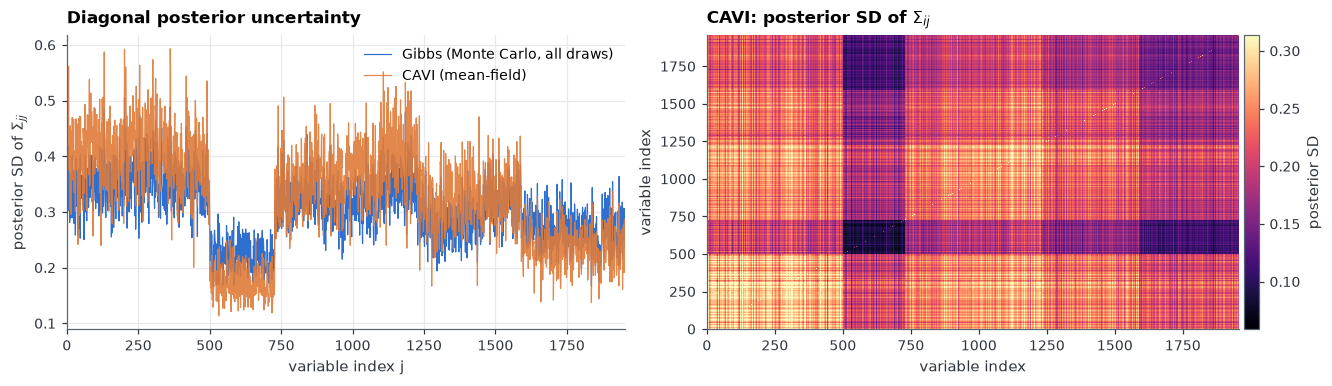

In [11]:
gs_sd_diag = np.sqrt(gs.Sigma_diag_var_)
vi_sd_diag = np.sqrt(np.diag(vi.Sigma_var_))
pair_var = float(gs.cov_Sigma([((0, 1), (0, 1))])[0])
pair_cov = float(gs.cov_Sigma([((0, 1), (2, 3))])[0])
print(f"posterior SD of Sigma_jj: Gibbs mean = {gs_sd_diag.mean():.3f}, "
      f"CAVI mean = {vi_sd_diag.mean():.3f}")
print(f"Gibbs: Var(Sigma_01) = {pair_var:.3e}, "
      f"Cov(Sigma_01, Sigma_23) = {pair_cov:.3e} "
      f"(all {gs.B_samples_.shape[0]} draws)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.05, 1.0]})
axes[0].plot(gs_sd_diag, color=C_GIBBS, lw=0.8,
             label="Gibbs (Monte Carlo, all draws)")
axes[0].plot(vi_sd_diag, color=C_CAVI, lw=0.8, alpha=0.9,
             label="CAVI (mean-field)")
axes[0].set_xlabel("variable index j")
axes[0].set_ylabel(r"posterior SD of $\Sigma_{jj}$")
axes[0].set_title("Diagonal posterior uncertainty", loc="left")
axes[0].set_xlim(0, P - 1)
axes[0].legend(loc="upper right")

im = axes[1].imshow(vi.Sigma_sd_, aspect="auto", origin="lower",
                    interpolation="nearest", cmap="magma",
                    vmax=float(np.percentile(vi.Sigma_sd_, 99)))
axes[1].set_xlabel("variable index")
axes[1].set_ylabel("variable index")
axes[1].set_title(r"CAVI: posterior SD of $\Sigma_{ij}$", loc="left")
axes[1].grid(False)
cb = fig.colorbar(im, ax=axes[1], pad=0.01)
cb.set_label("posterior SD")
plt.show()

## 5. MCMC mixing diagnostics: effective sample size via ArviZ

The heatmap and histogram summarize bulk, rank-normalized ESS for every loading entry; 400 is shown as a rule-of-thumb reference, not as a guarantee or a conclusion about any column. This section requires the optional ArviZ dependency. If needed, install it from the repository root with `python -m pip install -e ".[ess]"`.

B       min=     3.6  median=   881.3  mean=   827.0  max=  1336.5  (draws=1000)
sigma2  min=    66.7  median=   903.3  mean=   865.8  max=  1182.7  (draws=1000)


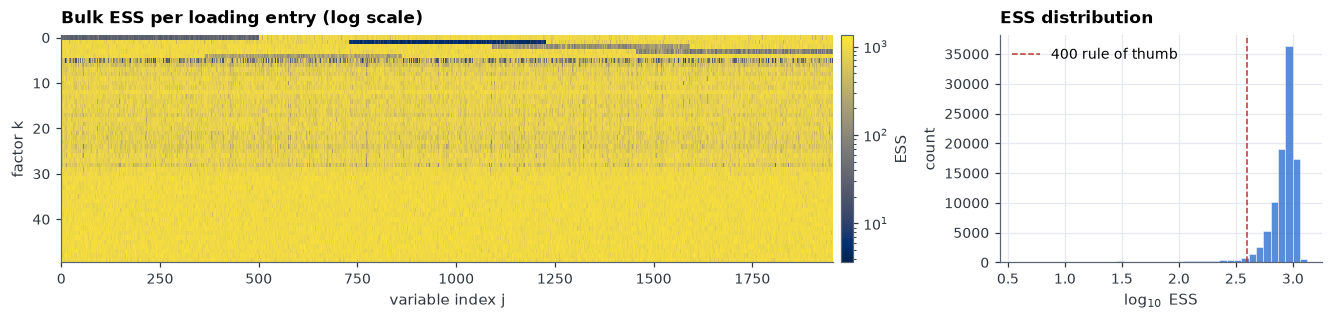

In [12]:
summary = gs.ess_summary()
for k, v in summary.items():
    print(f"{k:7s} min={v['min']:8.1f}  median={v['median']:8.1f}  "
          f"mean={v['mean']:8.1f}  max={v['max']:8.1f}  "
          f"(draws={v['n_draws']})")

from matplotlib.colors import LogNorm

ess_B = gs.ess()["B"]
vals = ess_B.ravel()
vals = vals[np.isfinite(vals) & (vals > 0)]
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8), constrained_layout=True,
                         gridspec_kw={"width_ratios": [2.4, 1.0]})
im = axes[0].imshow(ess_B.T, aspect="auto", interpolation="nearest",
                    norm=LogNorm(vmin=max(1.0, float(np.min(vals))),
                                 vmax=float(np.max(vals))), cmap="cividis")
axes[0].set_title("Bulk ESS per loading entry (log scale)", loc="left")
axes[0].set_xlabel("variable index j")
axes[0].set_ylabel("factor k")
axes[0].grid(False)
cb = fig.colorbar(im, ax=axes[0], pad=0.01)
cb.set_label("ESS")
axes[1].hist(np.log10(vals), bins=40, color=C_GIBBS, alpha=0.8,
             edgecolor="white", linewidth=0.4)
axes[1].axvline(np.log10(400.0), color=C_TRUE, ls="--", lw=1.0,
                label="400 rule of thumb")
axes[1].set_title("ESS distribution", loc="left")
axes[1].set_xlabel(r"$\log_{10}$ ESS")
axes[1].set_ylabel("count")
axes[1].legend(loc="upper left")
plt.show()

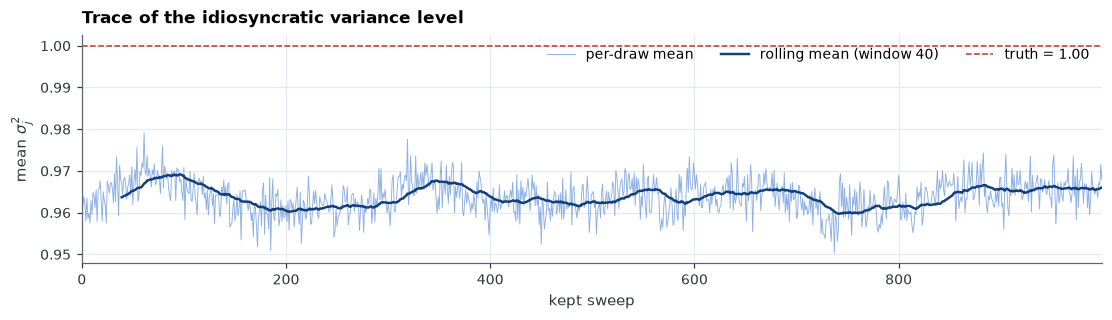

In [13]:
trace = gs.sigma2_samples_.mean(axis=1)
window = max(1, len(trace) // 25)
rolling = np.convolve(trace, np.ones(window) / window, mode="valid")

fig, ax = plt.subplots(figsize=(10, 2.8), constrained_layout=True)
ax.plot(trace, color=C_GIBBS, lw=0.6, alpha=0.55, label="per-draw mean")
ax.plot(np.arange(window - 1, len(trace)), rolling, color="#123f7a",
        lw=1.6, label=f"rolling mean (window {window})")
ax.axhline(float(s2_true[0]), color=C_TRUE, ls="--", lw=1.0,
           label=f"truth = {float(s2_true[0]):.2f}")
ax.set_xlabel("kept sweep")
ax.set_ylabel(r"mean $\sigma_j^2$")
ax.set_title("Trace of the idiosyncratic variance level", loc="left")
ax.set_xlim(0, len(trace) - 1)
ax.legend(loc="upper right", ncol=3)
plt.show()

## 6. Factor switching: RSP alignment and factor scores

Apply alignment explicitly after the original fitting, recovery, and ESS diagnostics above. For **K = 50**, RSP's default assignment backend requires Optax; if needed, install it from the repository root with `python -m pip install -e ".[rsp]"`. The Gibbs and CAVI alignments below are independent: neither uses the other estimator's loadings as a reference. Each alignment follows its estimator's resolved working precision.

- **Gibbs:** `gs.align_factors()` aligns every retained draw and updates `gs.B_hat_` to their aligned mean. `B_samples_` and ESS remain based on the original draws. Each draw's covariance is unchanged, but the plug-in `gs.Sigma_` can change because it uses the outer product of the new mean. `gs.n_factors()` continues to use the raw draws by default; `use_aligned=True` builds intervals from the aligned draws.
- **CAVI:** `vi.align_factors()` independently orients `mu_[None, :, :]` as one matrix, not as an MCMC sample. It exposes `mu_aligned_`, score means `eta_aligned_ = W_aligned_.T`, and transformed covariances `V_aligned_` and `Phi_aligned_`. The original parameters, `B_hat_`, `Sigma_`, and ELBO are unchanged. Both `method="credible"` and `method="linf"` use the original coordinates by default; `use_aligned=True` selects the aligned moments. A varimax rotation can change either count.
- **Scores on demand:** `gs.sample_factors(X, ...)` draws scores conditional on each retained loading/noise pair. Pass the original uncentered `X`; the fitted centering offset is applied internally. These are fresh conditional draws, not historical intermediate scores from the Gibbs sweeps.

The signed heatmaps use one color scale for each estimator's before/after pair. Orientation alone does not establish better recovery: the column-dependent MGP shrinkage prior is not invariant to general rotations or permutations. The CAVI outputs are transformed moments for interpretation, not a new CAVI optimum. The checks use one representative Gibbs draw and a small covariance submatrix to bound memory and computation.

In [14]:
# Save original-coordinate quantities so this section can be rerun safely.
gs_mean_raw = gs.B_samples_.mean(axis=0)
vi_mean_raw = vi.mu_.copy()
vi_elbo_before = tuple(vi.elbo_)
vi_count_before = vi.n_factors(method="credible")
vi_linf_count_before = vi.n_factors(method="linf", threshold=LINF_THRESHOLD)
check_features = np.unique(np.linspace(
    0, gs_mean_raw.shape[0] - 1, min(32, gs_mean_raw.shape[0]), dtype=int,
))
noise_block = np.diag(gs.sigma2_hat_[check_features])
gs_plugin_raw_block = (gs_mean_raw[check_features]
                       @ gs_mean_raw[check_features].T + noise_block)

gs.align_factors()
vi.align_factors()

for name, model in (("Gibbs", gs), ("CAVI", vi)):
    result = model.rsp_result_
    print(f"{name} RSP: status={int(result.status_code)}, "
          f"stop={result.diagnostics['stop_reason']}, "
          f"iterations={int(result.n_iter)}, final loss={float(result.loss_final):.6g}")
    print("  diagnostics:", result.diagnostics)

np.testing.assert_allclose(gs.B_hat_, gs.B_aligned_.mean(axis=0),
                           rtol=2e-5, atol=2e-6)
np.testing.assert_array_equal(vi.B_hat_, vi_mean_raw)
assert tuple(vi.elbo_) == vi_elbo_before
assert vi.n_factors(method="credible") == vi_count_before
assert vi.n_factors(method="linf", threshold=LINF_THRESHOLD) == vi_linf_count_before
print("Gibbs aligned mean:", gs.B_hat_.shape,
      "| CAVI transformed mean:", vi.mu_aligned_.shape)
print("CAVI B_hat_, ELBO and both original-coordinate factor counts are unchanged.")

print(f"CAVI aligned n_factors (credible): "
      f"{vi.n_factors(method='credible', use_aligned=True)}")
print(f"CAVI aligned n_factors (linf, threshold={LINF_THRESHOLD:g}): "
      f"{vi.n_factors(method='linf', threshold=LINF_THRESHOLD, use_aligned=True)}")

Gibbs RSP: status=1, stop=converged_threshold, iterations=4, final loss=194546
  diagnostics: {'initial_reference_near_zero': False, 'sp_path': 'elim', 'assignment_backend': 'optax', 'assignment_backend_requested': 'auto', 'polar': 'qdwh', 'varimax_svd_fallbacks': 1000, 'rotate_requested': True, 'varimax_applied': True, 'rotated': True, 'precision': 'float32', 'stop_reason': 'converged_threshold', 'nonfinite_fields': ()}
CAVI RSP: status=1, stop=converged_threshold, iterations=2, final loss=0
  diagnostics: {'initial_reference_near_zero': False, 'sp_path': 'elim', 'assignment_backend': 'optax', 'assignment_backend_requested': 'auto', 'polar': 'qdwh', 'varimax_svd_fallbacks': 0, 'rotate_requested': True, 'varimax_applied': True, 'rotated': True, 'precision': 'float64', 'stop_reason': 'converged_threshold', 'nonfinite_fields': ()}
Gibbs aligned mean: (1956, 50) | CAVI transformed mean: (1956, 50)
CAVI B_hat_, ELBO and both original-coordinate factor counts are unchanged.
CAVI aligned n_f

### Factor counts and all column infinity norms before / after alignment

Gibbs uses 95% marginal credible intervals. CAVI reports both 95% marginal credible intervals and the mean-loading rule with `LINF_THRESHOLD = 0.1`; equality is inactive. The four norm columns below are $\max_j |E[B_{jk}]|$ in the original and aligned coordinates. For Gibbs, the mean is taken over the corresponding raw or aligned draws **before** taking the absolute maximum. Every one of the 50 columns is printed separately, including the shrunk tail.

In [15]:
expected_priors = {
    "Gibbs": (3.0, 2.1, 3.1, 1.0, 1.0),
    "CAVI": (3.0, 2.1, 3.1, 1.0, 1.0),
}
for name, model in (("Gibbs", gs), ("CAVI", vi)):
    actual_priors = (model.nu, model.a1, model.a2, model.a_sigma, model.b_sigma)
    assert actual_priors == expected_priors[name]
    print(f"{name} hyperparameters: nu={model.nu:g}, a1={model.a1:g}, "
          f"a2={model.a2:g}, a_sigma={model.a_sigma:g}, b_sigma={model.b_sigma:g}")

assert (gs.precision_used_, vi.precision_used_) == ("float32", "float64")
assert (gs.center, vi.center) == (True, True)
assert (gs.standardize, vi.standardize) == (False, False)
assert (gs.n_iter, gs.burn_in, gs.thin, gs.seed, S) == (20000, 10000, 10, SAMPLER_SEED, 1000)
assert (vi.max_iter, vi.tol) == (1000, 1e-1)
print(f"Settings checked: data seed={DATA_SEED}, sampler/score seed={SAMPLER_SEED}, "
      f"K={K}, kept draws={S}")

factor_counts = {
    "Gibbs credible": (gs.n_factors(), gs.n_factors(use_aligned=True)),
    "CAVI credible": (vi.n_factors(method="credible"),
                      vi.n_factors(method="credible", use_aligned=True)),
    "CAVI linf": (vi.n_factors(method="linf", threshold=LINF_THRESHOLD),
                  vi.n_factors(method="linf", threshold=LINF_THRESHOLD,
                               use_aligned=True)),
}
print(f"true factors={K0}; credible level=0.95; "
      f"linf threshold={LINF_THRESHOLD:g}")
print(f"{'Factor-count method':<24} {'Before':>10} {'Aligned':>10}")
for method, (before, after) in factor_counts.items():
    print(f"{method:<24} {before:>10d} {after:>10d}")

column_linf = {
    "Gibbs before": np.max(np.abs(gs_mean_raw), axis=0),
    "Gibbs aligned": np.max(np.abs(gs.B_hat_), axis=0),
    "CAVI before": np.max(np.abs(vi.mu_), axis=0),
    "CAVI aligned": np.max(np.abs(vi.mu_aligned_), axis=0),
}
for norms in column_linf.values():
    assert norms.shape == (K,)
assert int((column_linf["CAVI before"] > np.asarray(
    LINF_THRESHOLD, dtype=vi.mu_.dtype)).sum()) == factor_counts["CAVI linf"][0]
assert int((column_linf["CAVI aligned"] > np.asarray(
    LINF_THRESHOLD, dtype=vi.mu_aligned_.dtype)).sum()) == factor_counts["CAVI linf"][1]

print("\nColumn infinity norms of posterior mean loadings (all columns):")
print(f"{'Column':>6}" + "".join(f"{label:>18}" for label in column_linf))
for k in range(K):
    print(f"{k + 1:6d}" + "".join(f"{norms[k]:18.9g}" for norms in column_linf.values()))

Gibbs hyperparameters: nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1
CAVI hyperparameters: nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1
Settings checked: data seed=11, sampler/score seed=2026, K=50, kept draws=1000


true factors=5; credible level=0.95; linf threshold=0.1
Factor-count method          Before    Aligned
Gibbs credible                    5          5
CAVI credible                    50         50
CAVI linf                        50         50

Column infinity norms of posterior mean loadings (all columns):
Column      Gibbs before     Gibbs aligned       CAVI before      CAVI aligned
     1        1.43683898        1.42642057        1.90197857         1.8904844
     2        1.29966938        1.28553283        1.75307674          1.743173
     3        1.27369046        1.27372956         1.6241706        1.61187343
     4        1.25028443        1.24924517        1.30171286        1.29051362
     5        1.04709089        1.04735482       0.887950332       0.889435591
     6      0.0313625671       0.030649811       0.557503563        0.60783204
     7      0.0170428492      0.0799800977       0.446731335       0.512746162
     8      0.0127584441      0.0404493324       0.46692175

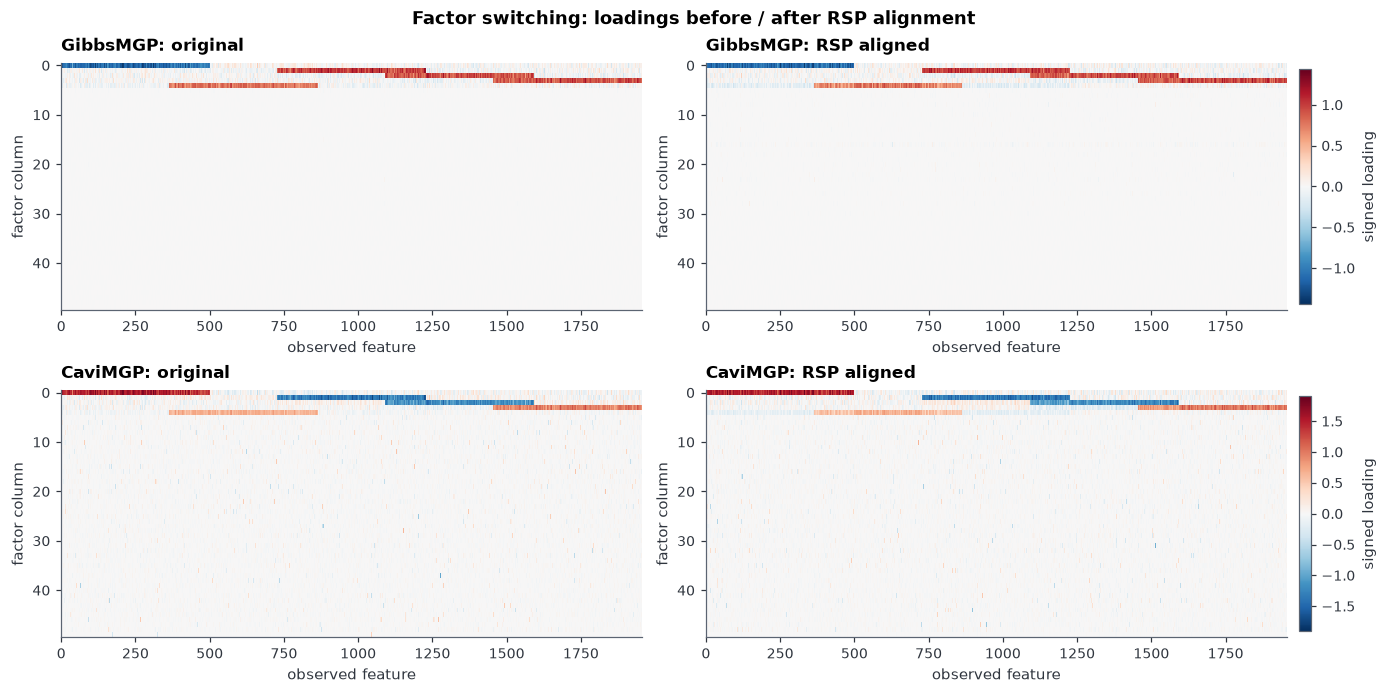

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.2), constrained_layout=True)
comparisons = (
    ("GibbsMGP", gs_mean_raw, gs.B_hat_),
    ("CaviMGP", vi_mean_raw, vi.mu_aligned_),
)
for row, (name, before, after) in enumerate(comparisons):
    limit = max(float(np.max(np.abs(before))), float(np.max(np.abs(after))), 1e-8)
    for col, (label, loadings) in enumerate((("original", before),
                                            ("RSP aligned", after))):
        ax = axes[row, col]
        im = ax.imshow(loadings.T, aspect="auto", interpolation="nearest",
                       cmap="RdBu_r", vmin=-limit, vmax=limit)
        ax.set_title(f"{name}: {label}", loc="left")
        ax.set_xlabel("observed feature")
        ax.set_ylabel("factor column")
        ax.grid(False)
    cb = fig.colorbar(im, ax=axes[row, :].tolist(), pad=0.01, shrink=0.95)
    cb.set_label("signed loading")
fig.suptitle("Factor switching: loadings before / after RSP alignment",
             fontweight="bold")
plt.show()

In [17]:
scores = gs.sample_factors(
    X, return_eta=True, return_eta_aligned=True, seed=SAMPLER_SEED, batch_size=32,
)
eta_sample = scores["eta_sample"]
eta_sample_aligned = scores["eta_sample_aligned"]
print("Gibbs eta_sample / eta_sample_aligned:",
      eta_sample.shape, eta_sample_aligned.shape, "(S, K, n)")
print("CAVI eta_aligned_ (posterior means):", vi.eta_aligned_.shape)
print("CAVI V_aligned_ / Phi_aligned_:", vi.V_aligned_.shape, vi.Phi_aligned_.shape)


def relative_difference(actual, expected):
    scale = max(float(np.linalg.norm(expected)), np.finfo(float).tiny)
    return float(np.linalg.norm(actual - expected)) / scale


# Compare paired scores for one draw and a small set of features.
s = gs.B_samples_.shape[0] // 2
B_raw_selected = gs.B_samples_[s, check_features]
B_aligned_selected = gs.B_aligned_[s, check_features]
common_raw = B_raw_selected @ eta_sample[s]
common_aligned = B_aligned_selected @ eta_sample_aligned[s]
np.testing.assert_allclose(common_aligned, common_raw, rtol=1e-4, atol=1e-4)
cov_raw = B_raw_selected @ B_raw_selected.T
cov_aligned = B_aligned_selected @ B_aligned_selected.T
np.testing.assert_allclose(cov_aligned, cov_raw, rtol=1e-4, atol=1e-4)
print(f"Gibbs draw {s}: relative B eta difference = "
      f"{relative_difference(common_aligned, common_raw):.3e}; "
      f"relative BB.T submatrix difference = "
      f"{relative_difference(cov_aligned, cov_raw):.3e}")

# CAVI score means and loadings transform together; no draw axis is needed.
vi_common_raw = vi.mu_ @ vi.W_.T
vi_common_aligned = vi.mu_aligned_ @ vi.eta_aligned_
np.testing.assert_allclose(vi_common_aligned, vi_common_raw, rtol=1e-4, atol=1e-4)
print("CAVI relative common-component difference:",
      f"{relative_difference(vi_common_aligned, vi_common_raw):.3e}")

gs_plugin_aligned_block = (gs.B_hat_[check_features]
                           @ gs.B_hat_[check_features].T + noise_block)
print("Gibbs plug-in Sigma_ relative change on selected features:",
      f"{relative_difference(gs_plugin_aligned_block, gs_plugin_raw_block):.3e}")
# The plug-in can change even though each aligned draw preserves BB.T.

Gibbs eta_sample / eta_sample_aligned: (1000, 50, 100) (1000, 50, 100) (S, K, n)
CAVI eta_aligned_ (posterior means): (50, 100)
CAVI V_aligned_ / Phi_aligned_: (1956, 50, 50) (50, 50)
Gibbs draw 500: relative B eta difference = 8.213e-07; relative BB.T submatrix difference = 8.895e-07
CAVI relative common-component difference: 6.838e-16
Gibbs plug-in Sigma_ relative change on selected features: 2.219e-03


## Summary

- Compare this execution's Gibbs credible-interval count and both CAVI counts (`credible` and `linf`, threshold `0.1`) before and after independent alignment against the true dimension $r=5$. Both estimators use `nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1`.
- The factor-selection table reports all 50 column infinity norms of the posterior mean loadings before and after alignment. For Gibbs this is the norm of the mean, not the mean of each draw's norm; linf factor selection remains a CAVI-only option. Use the covariance error tables and the top-$r$-by-norm principal-angle plot to assess recovery for this run.
- CAVI stopping status, run times, ESS diagnostics, full RSP diagnostics, and the raw/aligned common-component checks are computed and displayed in the cells above; interpret them from this execution rather than from previous runs.